# Multi-gene, human-only supplementary figures

The `FigureS_<GENE>` figures put one **species** per cell for a single gene. These transpose that: one **gene** per cell, all in human, so several examples can be compared side by side in the species with the deepest coverage.

| figure | genes |
|---|---|
| `SFigure_genes_brain` | CLTB, ENPP2, REEP6 |
| `SFigure_genes_EPN1_SERP2` | EPN1, SERP2 |

Every drawing primitive is **imported from `FigureS.py`**, not copied — the blocks are literally the same code that draws the cross-species figures, and only the cell loop differs. Setting `FIGURES_IMPORT_ONLY=1` before the import suppresses that module's own render loop.

Compositions live in `Figure3_helpers.MULTIGENE_FIGURES`, so adding a figure or reordering genes is a one-line edit there.

## Isoform picks

Navy is **the isoform with the highest median loading in heart**, not the second-ranked isoform in the gene's own claim tissue. When the top-heart isoform is already the red one, the rule falls through to the next highest — which happens for *EPN1*.

Ranking uses `ROLE_TISSUE['Human']['Heart']` (`Heart_Atrial_Appendage`), the same tissue the Heart loadings column displays, so a reader can look at that column and see the navy isoform is the highest in it. Pooling both chambers gives the same answer for all five genes.

The override is applied to the shared `ISOFORM_PICKS` table at run time, the way `FigureS.py` overrides VRK3 — each notebook has its own kernel, so the cross-species `FigureS_<GENE>` figures keep the picks they were published with.

In [1]:
import os
import pickle
import sys

FIG_DIR = '/project2/yangili1/cfbuenabadn/torino_paper/notebooks/Figure3'
for _p in (FIG_DIR, '/project2/yangili1/cfbuenabadn/torino_paper/analysis'):
    if _p not in sys.path:
        sys.path.insert(0, _p)

# Must be set before FigureS is imported: it suppresses that module's own
# render loop, which would otherwise redraw all 27 cross-species figures.
os.environ['FIGURES_IMPORT_ONLY'] = '1'

import numpy as np
from matplotlib import pyplot as plt

import FigureS as FS
import Figure3_helpers as _F3H
from Figure3_helpers import MULTIGENE_FIGURES, SUPP_GENE_FIGURES

PAGE_W = FS.PAGE_W

# ---------------------------------------------------------------------------
# Isoform picks for these figures only
#
# Navy is the isoform with the highest median loading in HEART rather than the
# second-ranked isoform in the gene's own claim tissue.  `resolve_picks`
# excludes the red isoform when resolving 'max_heart', so when the top-heart
# isoform IS the red one it falls through to the next highest — the rule asked
# for, already implemented for PHC1/Mouse.
#
# The override is applied to the shared table, the same way FigureS.py
# overrides VRK3: each notebook runs in its own kernel, so the cross-species
# FigureS_<GENE> figures keep the picks they were published with.
#
# The 'max_heart' sentinel itself cannot be used here: it matches the tissue id
# literally, and human panels carry GTEx ids (Heart_Atrial_Appendage,
# Heart_Left_Ventricle) rather than a bare 'Heart', so it resolves to None.
# The index is therefore computed explicitly, on the SAME tissue the Heart
# loadings column displays — ROLE_TISSUE['Human']['Heart'] — so a reader can
# look at that column and see the navy isoform is the highest one in it.
MULTIGENE_GENES = sorted({g for spec in MULTIGENE_FIGURES.values()
                          for g in spec['genes']})


def heart_medians(panel, tissues):
    """Median loading per iso_order entry across the given tissue ids."""
    ids = _F3H.merged_tissue_ids(panel)
    samples = ids.index[ids.isin(tissues)]
    EL = panel['el_annot']
    out = []
    for factor in panel['iso_order']:
        vals = EL.loc[samples, factor].dropna()
        out.append(float(np.median(vals)) if len(vals) else -np.inf)
    return np.array(out), len(samples)


def heart_tissue(panel):
    return FS.ROLE_TISSUE.get(panel['species'], FS.ROLE_TISSUE['_other'])['Heart']


def apply_heart_picks(genes, panels, red=0):
    """
    Navy := the isoform with the highest median loading in heart, excluding the
    red isoform so the rule falls through to the next highest when the top-heart
    isoform is already red.  Returns a report row per gene.
    """
    rows = []
    for gene in genes:
        panel = panels[gene]['Human']
        shown = heart_tissue(panel)
        meds, n = heart_medians(panel, [shown])
        order = np.argsort(-meds)
        top = int(order[0])
        navy = int(next(i for i in order if i != red))

        # Would pooling both chambers give a different answer?
        both = [t for t in _F3H.merged_tissue_ids(panel).unique()
                if str(t).startswith('Heart')]
        meds_b, n_b = heart_medians(panel, both)
        navy_b = int(next(i for i in np.argsort(-meds_b) if i != red))

        _F3H.ISOFORM_PICKS[(gene, 'Human')] = (red + 1, navy + 1)
        rows.append(dict(gene=gene, iso=panel['iso_order'], red=red, top=top,
                         navy=navy, fell_through=(top == red), n=n,
                         meds=meds, navy_both=navy_b, n_both=n_b,
                         tissues_both=both))
    return rows

## Data

The cross-species pickles plus `supp_panels_genes.pkl`, written by `prepare_supp_gene_panels.py` (human only, so it takes seconds rather than the ~45 min a cross-species set needs).

**CLTB is deliberately not re-prepared** — it comes from `supp_panels.pkl` with its Brain ranking, so this figure and `FigureS_CLTB` draw the same two isoforms.

Claim tissues for the other four follow the rule used throughout: the top-SSMD tissue among those where the gene is significant under the Figure 3b criterion. They are named in grey at the right of each cell, since the ranking is what picks the red and navy isoforms.

In [2]:
def load_gene_panels():
    """
    The cross-species pickles plus the human-only one.  CLTB comes from
    supp_panels.pkl so this figure and FigureS_CLTB draw the same isoforms.
    """
    panels = dict(FS.load_figure_data()['panels'])
    path = os.path.join(FIG_DIR, 'figure_data', 'supp_panels_genes.pkl')
    with open(path, 'rb') as fh:
        panels.update(pickle.load(fh))
    return panels

## Page plan

One gene per row, each spanning the full content width. That is the point of dropping the species axis: the structure block gets ~148 mm instead of the ~65 mm it has in a two-column cross-species cell, which is what makes the coverage readable.

`PAGE_H` is derived from the row heights, and the key band is derived from how many entries the key needs — a fixed band shorter than its contents overflows *upward* into the last gene's isoform rows.

In [3]:
# One gene per row, each spanning the full content width — the whole point of
# dropping the species axis is that the structure block gets twice the width it
# has in the cross-species figures.
TITLE_BAND  = 5.0        # figure title
GENE_LABEL_H = 3.0       # panel letter + italic gene name
ROW_GAP     = 4.0

# The key is centred inside its band, so a band shorter than the items needs
# overflows UPWARD into the last gene's isoform rows.  Derive it instead.
KEY_PITCH   = 4.2        # must match draw_isoform_key's default
KEY_PAD     = 2.0


def key_items(genes, panels):
    """Key entries: the grey row only when some gene has unpicked isoforms."""
    items = list(FS.ISOFORM_KEY)
    if any(len(panels[g]['Human']['iso_order'])
           > FS._n_iso_for(g, 'Human', panels[g]['Human']) for g in genes):
        items.append(('Other isoforms', FS.ISO_GREY))
    return items


def key_band_h(items):
    return len(items) * KEY_PITCH + KEY_PAD

PANEL_LETTERS = 'abcdefgh'


def _row_height(panel, cfg, first):
    """Block height for one gene row, mirroring FigureS._row_heights."""
    n_iso = FS._n_iso_for(cfg['gene'], 'Human', panel)
    struct = FS._blk_h(panel, n_iso, len(FS._tracks_for(panel, cfg)))
    load = FS.load_blk_h(n_iso + 1) + (FS.ROLE_LABEL_H if first else 0)
    return max(struct, load) + FS.STAT_H


def plan(genes, panels):
    """Per-gene configs and row heights, plus the derived page height."""
    cfgs, heights = [], []
    for i, gene in enumerate(genes):
        cfg = FS.gene_config(gene)
        cfg['gene'] = gene
        cfgs.append(cfg)
        heights.append(_row_height(panels[gene]['Human'], cfg, first=(i == 0)))

    page_h = (FS.MARGIN_T + TITLE_BAND
              + sum(GENE_LABEL_H + h + ROW_GAP for h in heights)
              + key_band_h(key_items(genes, panels)) + FS.MARGIN_B)
    return cfgs, heights, page_h

## Drawing

One cell per gene: panel letter, italic gene name, the claim tissue, then the structure block (coverage tracks + isoforms) and the loadings block.

The cross-species figures label the third loadings row ("Other isoforms") in place, where it runs across its own data — the loadings block is only ~21 mm wide. Here that row is named in the page key instead, which is why `row_labels=None`. The shared `draw_loading_block` is untouched, so the 27 existing figures are unaffected.

In [4]:
def draw_multigene_figure(key, panels):
    """One figure: a stack of single-gene, human-only cells."""
    spec = MULTIGENE_FIGURES[key]
    genes = spec['genes']
    cfgs, heights, page_h = plan(genes, panels)

    # FigureS's primitives read these module globals for their geometry.
    FS.PAGE_H = page_h
    FS.MAX_ROLES = max(len(c['roles']) for c in cfgs)
    FS._COMPOSITE_TITLES.clear()

    fig = plt.figure(figsize=(PAGE_W / 25.4, page_h / 25.4))
    fig.patch.set_facecolor('white')

    FS.fig_text(fig, PAGE_W / 2, FS.MARGIN_T, spec['title'],
                fontsize=FS.FS_TITLE, ha='center', va='top')

    cell_w = FS.GENE_X1 - FS.GENE_X0
    load_w = FS.load_block_w(FS.MAX_ROLES)
    struct_w = cell_w - FS.INNER_GAP - load_w

    y = FS.MARGIN_T + TITLE_BAND
    for i, (gene, cfg, row_h) in enumerate(zip(genes, cfgs, heights)):
        panel = panels[gene]['Human']
        first = (i == 0)
        n_iso = FS._n_iso_for(gene, 'Human', panel)

        FS.panel_letter(fig, PANEL_LETTERS[i], FS.MARGIN_L, y)
        FS.fig_text(fig, FS.MARGIN_L + 4.5, y, gene, fontsize=FS.FS_TITLE,
                    fontstyle='italic', ha='left', va='top')
        # The claim tissue sets the isoform ranking, so it is named, not implied.
        FS.fig_text(fig, PAGE_W - FS.MARGIN_R, y,
                    f'{cfg["roles"][0] if False else panel["tissue"]}-ranked',
                    fontsize=FS.FS_TICK, color='0.45', ha='right', va='top')

        y_top = y + GENE_LABEL_H + FS.STAT_H
        FS.draw_gene_block(
            fig, panel, FS.GENE_X0, y_top, struct_w, n_iso=n_iso,
            track_h=FS.TRACK_H, iso_h=FS.ISO_H, gap=FS.BLK_GAP,
            star_iso=cfg['star_iso'], star_end=cfg.get('star_end', 'last'),
            label_species=False, label_tracks=True,
            tracks=FS._tracks_for(panel, cfg), gene=gene)

        slots, ids = FS.build_slots(panel, cfg['roles'])
        FS.draw_loading_block(
            fig, panel, FS.GENE_X0 + struct_w + FS.INNER_GAP + FS.SLOT_TICKS,
            y_top, load_w - FS.SLOT_TICKS, slots, ids,
            row_h=FS.LOAD_ROW_H, gap=FS.LOAD_GAP, swatch_h=FS.SWATCH_H,
            show_labels=first, gene=gene, stats=panel.get('ssmd_stats'),
            ylabel='Loadings' if first else None,
            # The cross-species figures label the third loadings row in place,
            # where the label runs across its own data — the loadings block is
            # only ~21 mm wide.  Here the grey row is named in the key instead.
            row_labels=None,
            label_colors=[FS.ISO_RED, FS.ISO_MID, FS.ISO_NAVY, FS.ISO_GREY])

        y += GENE_LABEL_H + row_h + ROW_GAP

    # One key for the page, centred under the last gene.
    items = key_items(genes, panels)
    FS.draw_isoform_key(fig, PAGE_W / 2 - 24.0, y - ROW_GAP + KEY_PAD / 2,
                        48.0, key_band_h(items), items=items, note=None)

    FS._place_composite_titles(fig)
    return fig

## Render

Each figure as `.png`, `.pdf` and `.svg`; the SVG keeps text editable for Inkscape.

SFigure_genes_brain          CLTB, ENPP2, REEP6       180 x 137.9 mm -> SFigure_genes_brain.png/.pdf/.svg


SFigure_genes_EPN1_SERP2     EPN1, SERP2              180 x 99.3 mm -> SFigure_genes_EPN1_SERP2.png/.pdf/.svg

2 figures written


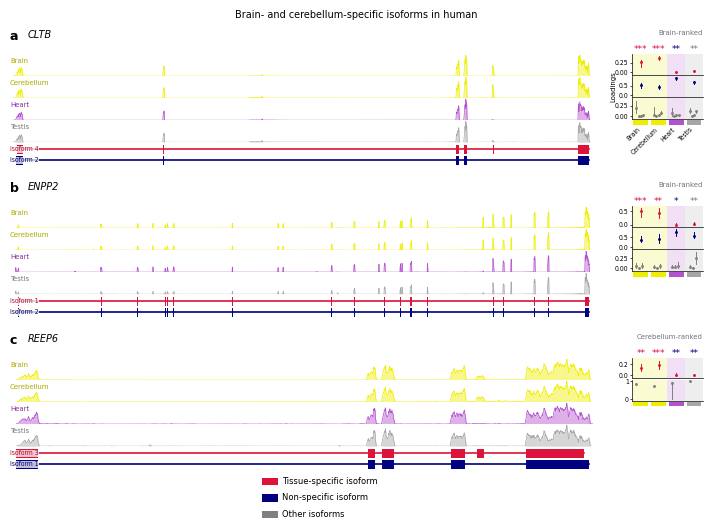

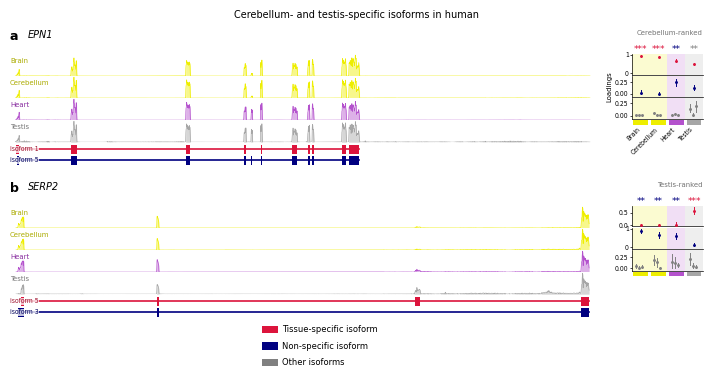

In [5]:
panels = load_gene_panels()
HEART_PICKS = apply_heart_picks(MULTIGENE_GENES, panels)

figs = {}
for _key in MULTIGENE_FIGURES:
    _missing = [g for g in MULTIGENE_FIGURES[_key]['genes']
                if g not in panels or 'Human' not in panels.get(g, {})]
    if _missing:
        print(f'{_key:12s} SKIPPED — no human panel for {", ".join(_missing)}')
        continue
    figs[_key] = draw_multigene_figure(_key, panels)
    _stem = f'SFigure_genes_{_key}'
    for _ext, _kw in (('png', dict(dpi=400)), ('pdf', {}), ('svg', {})):
        figs[_key].savefig(os.path.join(FIG_DIR, f'{_stem}.{_ext}'),
                           facecolor='white', **_kw)
    print(f'{_stem:28s} {", ".join(MULTIGENE_FIGURES[_key]["genes"]):24s} '
          f'{PAGE_W:.0f} x {figs[_key].get_size_inches()[1] * 25.4:.1f} mm '
          f'-> {_stem}.png/.pdf/.svg')
print(f'\n{len(figs)} figures written')

## Which isoform the heart rule picked

Printed so the choice is checkable: the red isoform, the top-heart isoform *before* exclusion, and the navy actually drawn. The last two differ exactly when the rule fell through, and the final column confirms that pooling both heart chambers would not change the result.

In [6]:
# Printed so the choice is checkable: the red isoform, the top-heart isoform
# before exclusion, and the navy actually drawn.  The last two differ exactly
# when the top-heart isoform is the red one and the rule fell through.
print(f'ranked on {heart_tissue(panels[MULTIGENE_GENES[0]]["Human"])}\n')
print(f'{"gene":7s} {"red":20s} {"top in heart":20s} {"navy drawn":20s} '
      f'{"fell through":13s} {"n":>4s}  both chambers agree?')
for _r in HEART_PICKS:
    _o = _r['iso']
    print(f'{_r["gene"]:7s} {_o[_r["red"]]:20s} {_o[_r["top"]]:20s} '
          f'{_o[_r["navy"]]:20s} {"yes" if _r["fell_through"] else "no":13s} '
          f'{_r["n"]:4d}  '
          f'{"yes" if _r["navy_both"] == _r["navy"] else "NO -> " + _o[_r["navy_both"]]}')

print('\nmedian heart loading per isoform (iso_order):')
for _r in HEART_PICKS:
    print(f'  {_r["gene"]:7s} ' + '  '.join(
        f'{_o}={_m:.3f}' for _o, _m in zip(_r['iso'], _r['meds'])))

ranked on Heart_Atrial_Appendage

gene    red                  top in heart         navy drawn           fell through     n  both chambers agree?
CLTB    CLTB.isoform_4       CLTB.isoform_2       CLTB.isoform_2       no             112  yes
ENPP2   ENPP2.isoform_1      ENPP2.isoform_2      ENPP2.isoform_2      no             112  yes
EPN1    EPN1.isoform_1       EPN1.isoform_1       EPN1.isoform_5       yes            112  yes
REEP6   REEP6.isoform_3      REEP6.isoform_1      REEP6.isoform_1      no             112  yes
SERP2   SERP2.isoform_5      SERP2.isoform_3      SERP2.isoform_3      no             112  yes

median heart loading per isoform (iso_order):
  CLTB    CLTB.isoform_4=0.003  CLTB.isoform_3=0.072  CLTB.isoform_2=0.883  CLTB.isoform_1=0.000  CLTB.isoform_5=0.025  CLTB.isoform_6=0.017
  ENPP2   ENPP2.isoform_1=0.001  ENPP2.isoform_4=0.037  ENPP2.isoform_2=0.756  ENPP2.isoform_5=0.027  ENPP2.isoform_6=0.059
  EPN1    EPN1.isoform_1=0.690  EPN1.isoform_4=0.016  EPN1.isoform_